# EDA: ข้อมูลราคาตลาด SPY, IEF และ GLD

## วัตถุประสงค์

สำรวจข้อมูลราคาของ ETF ทั้งสามสินทรัพย์ เพื่อทำความเข้าใจคุณภาพข้อมูล ผลตอบแทน ความผันผวน และความสัมพันธ์ระหว่างสินทรัพย์ ก่อนนำข้อมูลไปสร้าง features และโมเดลพยากรณ์ความเสี่ยง

ข้อมูลต้นทางคือ `market_prices_daily.parquet` ที่ผ่าน ingestion pipeline โดยหนึ่งแถวแทนหนึ่งสินทรัพย์ในหนึ่งวันซื้อขาย ช่วงวิเคราะห์และ warm-up อ้างอิง config ของข้อมูลที่โหลด


## 0. Environment และไลบรารีที่ใช้

ติดตั้งจาก **โฟลเดอร์หลักของโปรเจกต์** ก่อนเปิด notebook:

```bash
uv sync --locked --no-dev --group eda
uv run --locked --no-dev --group eda jupyter lab
```

เลือก kernel ของ `.venv` ในโปรเจกต์ หากใช้ pip ให้ติดตั้ง `python -m pip install -r requirements.txt` ใน environment นั้นแทน
คำสั่งติดตั้งอยู่ใน Markdown เพื่อไม่เปลี่ยน environment ระหว่างวิเคราะห์ ไม่ใช้ `!pip install` ภายใน notebook
เซลล์ถัดไปรวม imports และแสดง Python/เวอร์ชันที่ใช้ หากขาดไลบรารีต้องติดตั้งให้ครบก่อนทำต่อ

In [1]:
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas_market_calendars as mcal
from IPython.display import Markdown, display

%matplotlib inline

print("Python:", sys.version.split()[0])
print("Kernel executable:", sys.executable)
display(pd.DataFrame(
    [(name, version(name)) for name in (
        "pandas", "numpy", "matplotlib", "pandas-market-calendars",
        "pyarrow", "PyYAML", "ipykernel", "jupyterlab",
    )], columns=["library", "version"]
))

Python: 3.10.21
Kernel executable: D:\New folder (2)\datasci-and-dataen-project\.venv\Scripts\python.exe


,library,version
0,pandas,2.2.3
1,numpy,2.2.6
2,matplotlib,3.10.9
3,pandas-market-calendars,5.5.0
4,pyarrow,25.0.1
5,PyYAML,6.0.3
6,ipykernel,6.31.0
7,jupyterlab,4.6.6


## โหลดข้อมูลและขอบเขตที่คาดหวัง

อ่าน curated และ `config/ingestion.yaml` เพื่อกำหนดช่วงวิเคราะห์ รวมจำนวนวัน warm-up ก่อนวันเริ่มต้นตามปฏิทินตลาด
ใช้ช่วงวันที่ใน config โดยตรง ไม่ใช้วันแรก–วันสุดท้ายของข้อมูลเป็นขอบเขต เพื่อให้ตรวจพบข้อมูลที่หายต้นหรือท้ายช่วงได้
เลือก config ให้ตรงกับชุดข้อมูลที่ต้องการสำรวจ หากข้อมูลยังไม่ครบช่วงที่กำหนด การตรวจจะแสดงวันที่ขาด

In [2]:
# รองรับการเปิด notebook จาก root, notebooks/ หรือโฟลเดอร์ย่อยในโปรเจกต์
project_root = next((
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "config" / "ingestion.yaml").is_file() and (path / "src").is_dir()
), None)
if project_root is None:
    raise FileNotFoundError("เปิด notebook ภายในโฟลเดอร์โปรเจกต์ที่มี config/ingestion.yaml")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ingestion.config import load_config
from src.eda.quality import inspect_market_prices, add_historical_rv, inspect_historical_rv

config = load_config(project_root / "config" / "ingestion.yaml")
data_path = project_root / "data" / "curated" / "market_prices_daily.parquet"
if not data_path.is_file():
    raise FileNotFoundError(f"ไม่พบ {data_path}; กรุณารัน ingestion pipeline ก่อน")
source_df = pd.read_parquet(data_path)
if source_df.empty:
    raise ValueError("ข้อมูล curated ว่าง; กรุณารัน ingestion pipeline ก่อน")

# หาวันเริ่ม warm-up จากปฏิทินตลาด แทนการเดาจากข้อมูลที่มีอยู่
calendar = mcal.get_calendar(config["calendar"]["market"])
start_date = pd.Timestamp(config["date_range"]["start_date"])
end_date = pd.Timestamp(config["date_range"]["end_date"])
warmup_days = config["date_range"]["warmup_trading_days"]
lookback_years = max(2, warmup_days // 150 + 2)
while True:
    prior_sessions = calendar.schedule(
        start_date=start_date - pd.DateOffset(years=lookback_years),
        end_date=start_date - pd.Timedelta(days=1),
    ).index
    if len(prior_sessions) >= warmup_days:
        break
    lookback_years *= 2
fetch_start = prior_sessions[-warmup_days]
expected_sessions = calendar.schedule(start_date=fetch_start, end_date=end_date).index

print(f"จำนวนแถว: {source_df.shape[0]:,} | จำนวนคอลัมน์: {source_df.shape[1]}")
print("ช่วงที่ควรมีข้อมูล:", fetch_start.date(), "ถึง", end_date.date())
print("จำนวนวันซื้อขายที่ควรมีต่อสินทรัพย์:", len(expected_sessions))
df = source_df.copy()
display(df.head())

จำนวนแถว: 3,948 | จำนวนคอลัมน์: 12
ช่วงที่ควรมีข้อมูล: 2021-06-30 ถึง 2026-09-25
จำนวนวันซื้อขายที่ควรมีต่อสินทรัพย์: 1316


,date,ticker,adjusted_close,high,low,simple_return,log_return,is_anomaly_flagged,is_warmup_buffer,run_id,source_batch_id,ingested_at_utc
0,2021-06-30,GLD,165.630005,166.100006,164.289993,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.340704+00:00
1,2021-06-30,IEF,98.787727,98.933147,98.762067,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.334702+00:00
2,2021-06-30,SPY,399.087006,399.758274,398.266563,NaN,NaN,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.328193+00:00
3,2021-07-01,GLD,166.199997,166.880005,165.500000,0.003441,0.003435,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.340704+00:00
4,2021-07-01,IEF,98.716690,98.819400,98.579735,-0.000719,-0.000719,False,True,run_20261108_124004_bddf,yf_20261108_124004_bddf,2026-11-08 12:40:05.334702+00:00


## ภาพรวมข้อมูล

ตรวจสอบชนิดข้อมูลและจำนวนค่าที่ไม่ว่างในแต่ละคอลัมน์ จากนั้นสรุปจำนวนแถว ช่วงวันที่ และจำนวนแถว warm-up ของแต่ละสินทรัพย์


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3948 entries, 0 to 3947
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   date                3948 non-null   object             
 1   ticker              3948 non-null   object             
 2   adjusted_close      3948 non-null   float64            
 3   high                3948 non-null   float64            
 4   low                 3948 non-null   float64            
 5   simple_return       3945 non-null   float64            
 6   log_return          3945 non-null   float64            
 7   is_anomaly_flagged  3948 non-null   bool               
 8   is_warmup_buffer    3948 non-null   bool               
 9   run_id              3948 non-null   object             
 10  source_batch_id     3948 non-null   object             
 11  ingested_at_utc     3948 non-null   datetime64[us, UTC]
dtypes: bool(2), datetime64[us, UTC](1)

In [4]:
overview = df.groupby("ticker").agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    warmup_rows=("is_warmup_buffer", "sum"),
)
overview


,rows,first_date,last_date,warmup_rows
ticker,,,,
GLD,1316,2021-06-30,2026-09-25,61
IEF,1316,2021-06-30,2026-09-25,61
SPY,1316,2021-06-30,2026-09-25,61


## ตรวจคุณภาพข้อมูลและทวนสูตรผลตอบแทน

ตรวจ schema/types, คีย์ซ้ำ, ค่าว่าง, finite/positive prices, high-low consistency (tolerance 0.0001), flags และวันซื้อขายของทุก ticker ตาม config
คำนวณ simple/log return อิสระจากราคาที่เรียงตามเวลาโดยใช้ NumPy แล้วเทียบด้วย rtol=1e-9 และ atol=1e-12; แถวแรกของแต่ละ ticker ต้องว่างและแถวถัดไปต้อง finite

`issues` นับแถวที่ผิด ยกเว้นรายการ dtype นับคอลัมน์ และ missing sessions นับวันที่ขาด แถวเดียวอาจผิดหลายรายการจึงห้ามรวมเป็นจำนวนข้อมูลเสียทั้งหมด
ตารางแสดงตัวอย่างได้ไม่เกิน 5 รายการต่อ check หากมี FAIL จะหยุดก่อนสร้างสถิติ/กราฟ ไม่แก้หรือเติมข้อมูลเพื่อให้ผ่าน
Anomaly flag เป็น warning สำหรับทบทวนเหตุการณ์จริง ไม่ทำให้หยุดเพียงเพราะ return สูง; ตรวจเฉพาะว่า flag ตรงกับ threshold ใน config

In [5]:
df, quality_report = inspect_market_prices(source_df, config, expected_sessions)
display(quality_report)
if quality_report.status.eq("FAIL").any():
    display(quality_report.loc[quality_report.status.eq("FAIL")])
    raise ValueError("Data quality checks failed; ตรวจ examples ก่อนวิเคราะห์ต่อ")

analysis = df.loc[~df.is_warmup_buffer].copy()
if analysis.empty:
    raise ValueError("ไม่มีข้อมูลในช่วงวิเคราะห์")
print("Analysis rows by ticker:", analysis.groupby("ticker").size().to_dict())
print("Return nulls (warm-up only):")
display(df.groupby("ticker")[["simple_return", "log_return"]].agg(lambda values: values.isna().sum()))
print("Anomaly flags for review:", int(df.is_anomaly_flagged.sum()))

,check,ticker,issues,status,examples
0,numeric_dtypes,ALL,0,PASS,[]
1,boolean_dtypes,ALL,0,PASS,[]
2,valid_session_date,ALL,0,PASS,
3,duplicate_primary_key,ALL,0,PASS,
4,ticker_domain,ALL,0,PASS,
5,required_non_null:ticker,ALL,0,PASS,
6,required_non_null:is_anomaly_flagged,ALL,0,PASS,
7,required_non_null:is_warmup_buffer,ALL,0,PASS,
8,required_non_null:run_id,ALL,0,PASS,
9,required_non_null:source_batch_id,ALL,0,PASS,


Analysis rows by ticker: {'GLD': 1255, 'IEF': 1255, 'SPY': 1255}
Return nulls (warm-up only):


,simple_return,log_return
ticker,,
GLD,1,1
IEF,1,1
SPY,1,1


Anomaly flags for review: 0


## ทวนสูตร RV และความพร้อมของช่วงวิเคราะห์

คำนวณจากข้อมูลรวม warm-up โดยใช้เฉพาะผลตอบแทนย้อนหลังถึงวัน t ตาม feature contract:
`RV(n,t) = sqrt(252/n × sum(r²))` เป็น annualized decimal แบบไม่หักค่าเฉลี่ย

ตรวจอิสระด้วย NumPy dot product ของแต่ละหน้าต่างย้อนหลัง (ไม่ใช้ pandas rolling ในตัวตรวจ) รวมตำแหน่ง warm-up null และกำหนดให้ RV ทุกช่วง 5/20/60 วันในช่วงวิเคราะห์ต้อง finite และไม่ติดลบ
หากไม่ผ่านจะหยุดก่อนสรุปผล

In [6]:
df = add_historical_rv(df)
rv_checks = inspect_historical_rv(df)
display(rv_checks)
if rv_checks.status.eq("FAIL").any():
    raise ValueError("RV formula/readiness checks failed; ตรวจ example_dates ก่อนทำต่อ")
analysis = df.loc[~df.is_warmup_buffer].copy()

,ticker,window,formula_mismatches,invalid_analysis_rows,max_abs_error,status,example_dates
0,GLD,5,0,0,1.110223e-16,PASS,[]
1,GLD,20,0,0,1.110223e-16,PASS,[]
2,GLD,60,0,0,1.110223e-16,PASS,[]
3,IEF,5,0,0,1.283695e-16,PASS,[]
4,IEF,20,0,0,2.775558e-17,PASS,[]
5,IEF,60,0,0,2.775558e-17,PASS,[]
6,SPY,5,0,0,1.207368e-15,PASS,[]
7,SPY,20,0,0,1.110223e-16,PASS,[]
8,SPY,60,0,0,5.551115e-17,PASS,[]


## การกระจายของผลตอบแทน
สรุป log return รายวันในช่วงวิเคราะห์ หน่วยเป็น decimal; kurtosis เป็น excess kurtosis (normal = 0) ค่าปลายสุดเป็นจุดที่ควรตรวจสอบ ไม่ใช่หลักฐานว่าข้อมูลผิด


In [7]:
returns_summary = analysis.groupby('ticker')['log_return'].agg(['count','mean','median','std','min','max','skew'])
returns_summary['kurtosis_excess'] = analysis.groupby('ticker')['log_return'].apply(lambda s: s.kurt())
returns_summary['q01'] = analysis.groupby('ticker')['log_return'].quantile(.01)
returns_summary['q99'] = analysis.groupby('ticker')['log_return'].quantile(.99)
print(returns_summary.round(5).to_string())


        count     mean   median      std      min      max     skew  kurtosis_excess      q01      q99
ticker                                                                                                
GLD      1255  0.00070  0.00080  0.01190 -0.10841  0.06165 -0.79971          7.68662 -0.03189  0.03036
IEF      1255 -0.00008 -0.00010  0.00486 -0.01793  0.02228  0.15630          1.10791 -0.01191  0.01273
SPY      1255  0.00049  0.00061  0.01081 -0.06033  0.09986  0.15217          7.92202 -0.02972  0.02566


## ตรวจสอบผลตอบแทนสุดขั้ว: วันใดควรทบทวน?
เลือก 5 วันตามขนาดสัมบูรณ์ของ simple return ภายในแต่ละ ticker จากช่วง analysis เพื่อใช้ตรวจสอบ ไม่ได้หมายความว่าข้อมูลผิด ราคาในวันก่อนหน้าใช้ลำดับการซื้อขายของ ticker เดียวกัน และแสดงค่าสูงสุด/ต่ำสุดแยกด้วย


In [8]:
review_data = df.sort_values(['ticker', 'date']).copy()
review_data['previous_close'] = review_data.groupby('ticker').adjusted_close.shift()
review_data['simple_return_pct'] = review_data.simple_return * 100
review_analysis = review_data.loc[~review_data.is_warmup_buffer & review_data.simple_return.notna()].copy()
review_analysis['magnitude'] = review_analysis.simple_return.abs()
events = review_analysis.sort_values(['ticker', 'magnitude', 'date'], ascending=[True, False, True]).groupby('ticker', sort=True).head(5).copy()
events['rank'] = events.groupby('ticker').cumcount() + 1
cols = ['ticker','rank','date','adjusted_close','previous_close','simple_return_pct','log_return','is_anomaly_flagged']
display(events[cols].reset_index(drop=True))
print('ค่าสูงสุดและต่ำสุดรายสินทรัพย์ (simple return)')
display(review_analysis.sort_values(['ticker','simple_return','date']).groupby('ticker').apply(lambda g: g.iloc[[0,-1]].drop_duplicates(), include_groups=False)[['date','simple_return_pct','log_return']])


,ticker,rank,date,adjusted_close,previous_close,simple_return_pct,log_return,is_anomaly_flagged
0,GLD,1,2026-01-30,444.950012,495.899994,-10.274245,-0.108412,False
1,GLD,2,2025-10-21,377.239990,403.149994,-6.426889,-0.066427,False
2,GLD,3,2026-02-03,454.290009,427.130005,6.358721,0.061647,False
3,GLD,4,2026-03-03,468.140015,490.000000,-4.461222,-0.045638,False
4,GLD,5,2025-12-29,398.600006,416.739990,-4.352830,-0.044504,False
5,IEF,1,2022-09-28,84.004517,82.153961,2.252546,0.022276,False
6,IEF,2,2022-11-10,83.870049,82.029366,2.243932,0.022191,False
7,IEF,3,2023-03-10,85.600601,84.052696,1.841589,0.018248,False
8,IEF,4,2022-06-13,85.526993,87.074310,-1.777008,-0.017930,False
9,IEF,5,2022-09-26,82.718666,84.117462,-1.662908,-0.016769,False


ค่าสูงสุดและต่ำสุดรายสินทรัพย์ (simple return)


date  simple_return_pct  log_return
ticker                                               
GLD    1151 2026-01-30         -10.274245   -0.108412
       1153 2026-02-03           6.358721    0.061647
IEF    1556 2022-06-13          -1.777008   -0.017930
       1630 2022-09-28           2.252546    0.022276
SPY    3577 2025-04-04          -5.854304   -0.060327
       3580 2025-04-09          10.501934    0.099863

## บริบทรอบเหตุการณ์
ตรวจอันดับหนึ่งของแต่ละ ticker และ GLD 2026-01-30 หากมี โดยแสดงข้อมูลสูงสุด 5 วันซื้อขายก่อนและหลัง หากอยู่ใกล้ขอบจะแสดงเท่าที่มี


GLD 2026-01-30: ก่อน 5 วัน หลัง 5 วัน


,date,adjusted_close,high,low,simple_return_pct,log_return,is_anomaly_flagged
1146,2026-01-23,458.000000,458.750000,453.450012,1.374530,0.013652,False
1147,2026-01-26,464.700012,469.279999,460.359985,1.462885,0.014523,False
1148,2026-01-27,476.100006,476.489990,463.950012,2.453194,0.024236,False
1149,2026-01-28,494.559998,495.880005,481.250000,3.877335,0.038041,False
1150,2026-01-29,495.899994,509.700012,468.510010,0.270947,0.002706,False
1151,2026-01-30,444.950012,470.059998,430.799988,-10.274245,-0.108412,False
1152,2026-02-02,427.130005,440.779999,422.549988,-4.004946,-0.040874,False
1153,2026-02-03,454.290009,459.000000,448.309998,6.358721,0.061647,False
1154,2026-02-04,453.970001,463.100006,445.709991,-0.070441,-0.000705,False
1155,2026-02-05,441.880005,450.899994,440.350006,-2.663171,-0.026993,False


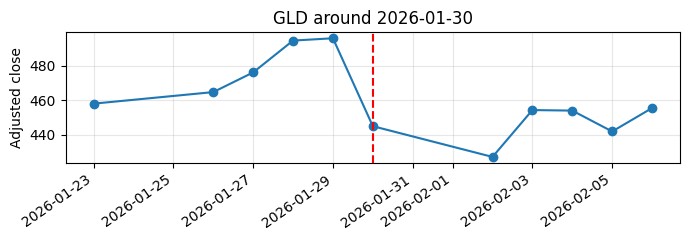

IEF 2022-09-28: ก่อน 5 วัน หลัง 5 วัน


,date,adjusted_close,high,low,simple_return_pct,log_return,is_anomaly_flagged
309,2022-09-21,85.299019,85.385898,84.534475,0.398800,0.003980,False
310,2022-09-22,84.013229,84.465011,83.917661,-1.507391,-0.015189,False
311,2022-09-23,84.117462,84.247784,83.648308,0.124067,0.001240,False
312,2022-09-26,82.718666,83.665664,82.597034,-1.662908,-0.016769,False
313,2022-09-27,82.153961,82.840316,82.110525,-0.682681,-0.006850,False
314,2022-09-28,84.004517,84.100085,82.988013,2.252546,0.022276,False
315,2022-09-29,83.613533,83.908929,83.309454,-0.465432,-0.004665,False
316,2022-09-30,83.396355,84.169588,83.109655,-0.259741,-0.002601,False
317,2022-10-03,84.386154,85.004208,83.994426,1.186862,0.011799,False
318,2022-10-04,84.560219,85.047696,84.403529,0.206272,0.002061,False


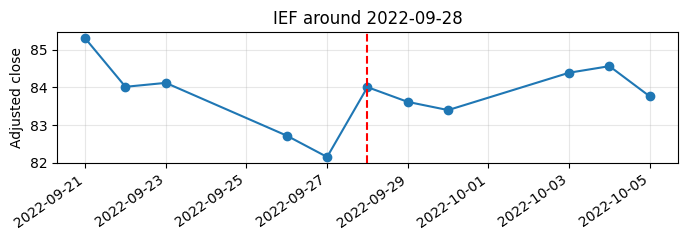

SPY 2025-04-09: ก่อน 5 วัน หลัง 5 วัน


,date,adjusted_close,high,low,simple_return_pct,log_return,is_anomaly_flagged
943,2025-04-02,555.308838,558.161483,545.757253,0.632842,0.006308,False
944,2025-04-03,527.942810,539.028879,527.942810,-4.928074,-0.050536,False
945,2025-04-04,497.035431,517.289464,496.819019,-5.854304,-0.060327,False
946,2025-04-07,496.150146,514.633533,473.938563,-0.178113,-0.001783,False
947,2025-04-08,488.379028,516.413968,481.178460,-1.566284,-0.015787,False
948,2025-04-09,539.668274,539.668274,485.004991,10.501934,0.099863,False
949,2025-04-10,516.020569,524.795007,501.009553,-4.381896,-0.044808,False
950,2025-04-11,525.227783,527.677145,511.584103,1.784273,0.017685,False
951,2025-04-14,530.323303,535.399142,525.149120,0.970154,0.009655,False
952,2025-04-15,528.837891,534.366185,528.050956,-0.280096,-0.002805,False


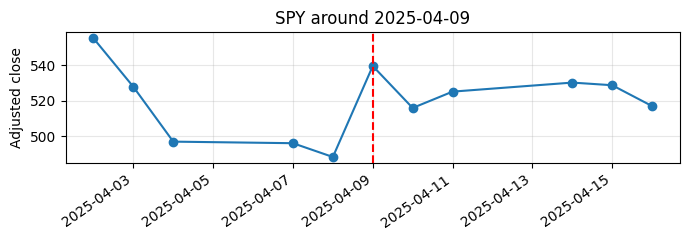

In [9]:
selected = events.loc[events['rank'].eq(1), ['ticker','date']].copy()
special = review_analysis.loc[review_analysis.ticker.eq('GLD') & review_analysis.date.eq(pd.Timestamp('2026-01-30')), ['ticker','date']]
selected = pd.concat([selected, special]).drop_duplicates().sort_values(['ticker','date'])
for event in selected.itertuples(index=False):
    group = review_data.loc[review_data.ticker.eq(event.ticker)].reset_index(drop=True)
    position = group.index[group.date.eq(event.date)][0]
    before, after = min(5, position), min(5, len(group)-position-1)
    print(f'{event.ticker} {event.date:%Y-%m-%d}: ก่อน {before} วัน หลัง {after} วัน')
    display(group.iloc[position-before:position+after+1][['date','adjusted_close','high','low','simple_return_pct','log_return','is_anomaly_flagged']])
    fig, ax = plt.subplots(figsize=(7, 2.5))
    window = group.iloc[position-before:position+after+1]
    ax.plot(window.date, window.adjusted_close, marker='o'); ax.axvline(event.date, color='red', linestyle='--')
    ax.set_title(f'{event.ticker} around {event.date:%Y-%m-%d}'); ax.set_ylabel('Adjusted close'); ax.grid(alpha=.3)
    fig.autofmt_xdate(rotation=35); plt.tight_layout(); plt.show()


## หลักฐาน: raw snapshot และแหล่งภายนอก
ตรวจ snapshot เฉพาะ batch ที่ระบุใน curated และตรวจ manifest ว่า auto_adjust=True ก่อนเปรียบเทียบ Close และ return ที่คำนวณจากวันก่อนหน้า หากไม่พบไฟล์จะแสดงข้อจำกัดโดยไม่หยุด notebook การตรงกันยืนยันเพียงความสอดคล้องภายใน Yahoo ชุดเดียวกัน ไม่ใช่การยืนยันจากแหล่งอิสระ


In [10]:
import json
from src.eda.quality import raw_price_returns
raw_results = []
for event in selected.itertuples(index=False):
    group = review_data.loc[review_data.ticker.eq(event.ticker)].reset_index(drop=True)
    pos = group.index[group.date.eq(event.date)][0]
    row = group.iloc[pos]
    result = {'ticker': event.ticker, 'date': event.date, 'status': 'ยังยืนยันไม่ได้: ไม่พบ raw ที่เชื่อมได้'}
    if pos > 0 and row.source_batch_id == group.iloc[pos-1].source_batch_id:
        folder = project_root / 'data' / 'raw' / str(row.source_batch_id)
        manifest_path, raw_path = folder / 'manifest.json', folder / 'raw_prices.csv'
        if manifest_path.is_file() and raw_path.is_file():
            try:
                manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
                raw = pd.read_csv(raw_path, parse_dates=['date'])
                subset = raw.loc[raw.ticker.eq(event.ticker) & raw.date.isin([event.date, group.iloc[pos-1].date])].set_index('date')
                if manifest.get('source_batch_id') == row.source_batch_id and manifest.get('auto_adjust') is True and len(subset) == 2 and subset.index.is_unique:
                    current = float(subset.loc[event.date, 'Close'])
                    previous = float(subset.loc[group.iloc[pos-1].date, 'Close'])
                    returns = raw_price_returns(previous, current)
                    if returns is None:
                        result['status'] = 'ยังยืนยันไม่ได้: ราคา raw ไม่ผ่านเงื่อนไข'
                    else:
                        raw_simple, raw_log = returns
                        result.update({'raw_file': str(raw_path.relative_to(project_root)), 'raw_close': current, 'raw_previous_close': previous,
                                       'raw_simple_return': raw_simple, 'raw_log_return': raw_log})
                        matches = np.allclose([current, previous, raw_simple, raw_log], [row.adjusted_close, row.previous_close, row.simple_return, row.log_return], rtol=1e-9, atol=1e-12)
                        result['status'] = 'สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ' if matches else 'ไม่สอดคล้อง: ตรวจต่อ' 
                else:
                    result['status'] = 'ยังยืนยันไม่ได้: batch, adjustment หรือแถว raw ไม่ครบ'
            except (OSError, ValueError, KeyError, TypeError) as exc:
                result['status'] = f'ยังยืนยันไม่ได้: อ่าน raw ไม่สำเร็จ ({exc})'
    raw_results.append(result)
display(pd.DataFrame(raw_results))


,ticker,date,status,raw_file,raw_close,raw_previous_close,raw_simple_return,raw_log_return
0,GLD,2026-01-30,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ,data\raw\yf_20261108_124004_bddf\raw_prices.csv,444.950012,495.899994,-0.102742,-0.108412
1,IEF,2022-09-28,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ,data\raw\yf_20261108_124004_bddf\raw_prices.csv,84.004517,82.153961,0.022525,0.022276
2,SPY,2025-04-09,สอดคล้องกับ raw; ยังไม่ยืนยันอิสระ,data\raw\yf_20261108_124004_bddf\raw_prices.csv,539.668274,488.379028,0.105019,0.099863


### ข้อสรุปและข้อจำกัด
- **GLD 2026-01-30:** [Dow Jones ผ่าน Tiger Brokers](https://www.itiger.com/news/2607024866) เผยแพร่ 30 มกราคม 2026 เวลา 16:35 ET รายงานราคาปิด 444.95 ดอลลาร์และลดลง 10.3% ในวันนั้น สนับสนุนทิศทางและขนาดโดยประมาณ แต่ไม่ยืนยัน adjusted return ทุกหลัก หรือวิธีปรับราคาย้อนหลัง
- **เหตุการณ์อันดับหนึ่งของ SPY และ IEF:** ตรวจความสอดคล้องกับ raw ตามตารางข้างต้น ยังไม่ได้ยืนยันจากแหล่งอิสระ
- หาก raw ขาดหรือไม่ตรง ให้ตรวจต่อโดยไม่ใช้ snapshot คนละ batch ทดแทนโดยอัตโนมัติ; คงค่าต้นฉบับไว้ระหว่างตรวจ การคงค่าไม่ใช่การรับรองว่าถูกต้อง
- เกณฑ์ flag คือ `abs(simple_return) > 0.20`; การไม่ติด flag ไม่ยืนยันความถูกต้อง และการติด flag ไม่พิสูจน์ว่าข้อมูลผิด


## ความผันผวนย้อนหลังและความสัมพันธ์

ใช้ RV ที่ผ่านการทวนสูตรในส่วนก่อนหน้า ส่วน correlation ใช้ log return ของทั้งสาม ETF บนวันซื้อขายเดียวกัน เป็น historical proxy
ตรวจว่าชุดวันที่ครบและไม่มีค่าว่างก่อนคำนวณ เพื่อไม่ใช้คู่สินทรัพย์ที่มีวันสังเกตต่างกัน

In [11]:
wide = df.pivot(index='date', columns='ticker', values='log_return').sort_index()
analysis_wide = wide.loc[analysis.date.min():analysis.date.max()]
if wide.isna().iloc[1:].any().any() or analysis_wide.isna().any().any():
    raise ValueError("Correlation requires aligned complete returns for all assets")
print('RV summary (annualized decimal):')
print(analysis.groupby('ticker')[[f'rv_{n}d' for n in (5,20,60)]].agg(['mean','median','max']).round(4).to_string())
print('\nPearson correlation (analysis period):')
print(analysis_wide.corr().round(3).to_string())
pairs = [('SPY','IEF'),('SPY','GLD'),('IEF','GLD')]
rolling_corr = pd.DataFrame({f'{a}-{b}': wide[a].rolling(20, min_periods=20).corr(wide[b]) for a,b in pairs}).loc[analysis.date.min():analysis.date.max()]
print('\nRolling 20-day correlations:')
print(rolling_corr.agg(['min','median','max']).round(3).to_string())


RV summary (annualized decimal):
         rv_5d                  rv_20d                  rv_60d                
          mean  median     max    mean  median     max    mean  median     max
ticker                                                                        
GLD     0.1635  0.1439  0.9703  0.1715  0.1470  0.5826  0.1742  0.1530  0.4255
IEF     0.0703  0.0637  0.2308  0.0729  0.0674  0.1435  0.0737  0.0702  0.1199
SPY     0.1481  0.1301  0.9097  0.1556  0.1363  0.5243  0.1600  0.1363  0.3394

Pearson correlation (analysis period):
ticker    GLD    IEF    SPY
ticker                     
GLD     1.000  0.300  0.152
IEF     0.300  1.000  0.097
SPY     0.152  0.097  1.000

Rolling 20-day correlations:
        SPY-IEF  SPY-GLD  IEF-GLD
min      -0.798   -0.736   -0.482
median    0.135    0.184    0.380
max       0.884    0.907    0.844


## ความไวของข้อสรุปต่อเหตุการณ์สุดขั้ว

**คำถาม:** สถิติเปลี่ยนมากแค่ไหน เมื่อเว้นวันรุนแรงบางวันเพื่อเปรียบเทียบ?

เปรียบเทียบ 3 กรณี: **ข้อมูลเต็ม**, **เว้นวันสุดขั้ว 1 วัน** และ **เว้นวันสุดขั้วสูงสุด 5 วัน** ต่อสินทรัพย์ เลือกจากขนาด simple return ตามรายการก่อนหน้า และใช้วันชุดเดียวกันกับสถิติทุกตัว

ตารางแรกแสดงระดับและการกระจาย ส่วนตารางที่สองแสดงรูปร่างการกระจาย Mean, median และ std มีหน่วยเป็น **100 × daily log return**; std ใช้ ddof=1 และ excess kurtosis มีค่าอ้างอิง normal = 0

ข้อมูลเต็มยังเป็นผลหลัก การเว้นวันเป็นการทดลองเพื่อเข้าใจอิทธิพล ไม่ได้แปลว่าข้อมูลสะอาดกว่าหรือควรตัดวันเหล่านั้นทิ้ง

In [12]:
from src.eda.quality import distribution_sensitivity, peak_rv_contributions, correlation_sensitivity

case_labels = {
    'top-0': 'ข้อมูลเต็ม',
    'top-1': 'เว้นสูงสุด 1 วัน',
    'top-5': 'เว้นสูงสุด 5 วัน',
}
dist_sensitivity = distribution_sensitivity(analysis, events)
dist_display = dist_sensitivity.assign(case=dist_sensitivity['case'].map(case_labels))

print('ระดับและการกระจายของ daily log return')
display(dist_display[[
    'ticker', 'case', 'n', 'excluded', 'mean_log_pct', 'median_log_pct',
    'std_log_pct', 'std_change_pct',
]].round(4).rename(columns={
    'ticker': 'สินทรัพย์', 'case': 'กรณี', 'n': 'วันที่เหลือ', 'excluded': 'วันที่เว้น',
    'mean_log_pct': 'Mean (%)', 'median_log_pct': 'Median (%)',
    'std_log_pct': 'Std (%)', 'std_change_pct': 'Std เปลี่ยน (%)',
}))

print('รูปร่างการกระจาย — ส่วนต่างเทียบกับข้อมูลเต็ม')
display(dist_display[[
    'ticker', 'case', 'skew', 'delta_skew', 'kurtosis', 'delta_kurtosis',
]].round(4).rename(columns={
    'ticker': 'สินทรัพย์', 'case': 'กรณี', 'skew': 'Skewness',
    'delta_skew': 'ส่วนต่าง skewness', 'kurtosis': 'Excess kurtosis',
    'delta_kurtosis': 'ส่วนต่าง excess kurtosis',
}))

ระดับและการกระจายของ daily log return


,สินทรัพย์,กรณี,วันที่เหลือ,วันที่เว้น,Mean (%),Median (%),Std (%),Std เปลี่ยน (%)
0,GLD,ข้อมูลเต็ม,1255,0,0.0701,0.0804,1.1899,0.0000
1,GLD,เว้นสูงสุด 1 วัน,1254,1,0.0788,0.0818,1.1498,-3.3750
2,GLD,เว้นสูงสุด 5 วัน,1250,5,0.0866,0.0837,1.1075,-6.9242
3,IEF,ข้อมูลเต็ม,1255,0,-0.0080,-0.0104,0.4859,0.0000
4,IEF,เว้นสูงสุด 1 วัน,1254,1,-0.0098,-0.0104,0.4820,-0.8087
5,IEF,เว้นสูงสุด 5 วัน,1250,5,-0.0103,-0.0104,0.4707,-3.1200
6,SPY,ข้อมูลเต็ม,1255,0,0.0494,0.0615,1.0813,0.0000
7,SPY,เว้นสูงสุด 1 วัน,1254,1,0.0414,0.0612,1.0446,-3.3905
8,SPY,เว้นสูงสุด 5 วัน,1250,5,0.0497,0.0634,1.0027,-7.2678


รูปร่างการกระจาย — ส่วนต่างเทียบกับข้อมูลเต็ม


,สินทรัพย์,กรณี,Skewness,ส่วนต่าง skewness,Excess kurtosis,ส่วนต่าง excess kurtosis
0,GLD,ข้อมูลเต็ม,-0.7997,0.0000,7.6866,0.0000
1,GLD,เว้นสูงสุด 1 วัน,-0.2267,0.5730,2.7731,-4.9135
2,GLD,เว้นสูงสุด 5 วัน,-0.1157,0.6840,1.4329,-6.2537
3,IEF,ข้อมูลเต็ม,0.1563,0.0000,1.1079,0.0000
4,IEF,เว้นสูงสุด 1 วัน,0.0916,-0.0647,0.8773,-0.2306
5,IEF,เว้นสูงสุด 5 วัน,0.0484,-0.1079,0.3932,-0.7147
6,SPY,ข้อมูลเต็ม,0.1522,0.0000,7.9220,0.0000
7,SPY,เว้นสูงสุด 1 วัน,-0.4964,-0.6486,2.9672,-4.9549
8,SPY,เว้นสูงสุด 5 วัน,-0.3499,-0.5021,1.4800,-6.4420


### อะไรขับเคลื่อน RV สูงสุด?

ใช้หน้าต่าง 5/20/60 วันซื้อขายเดิม รวมข้อมูล warm-up และเลือกวันที่แรกหาก RV สูงสุดเท่ากัน ไม่ลบวันหรือคำนวณ rolling ใหม่

ตารางแรกระบุหน้าต่างที่ RV สูงสุด ส่วนตารางที่สองบอกว่าวันใดมีส่วนร่วมมากที่สุด **สัดส่วนเป็นส่วนของผลรวม r² หรือ RV² ไม่ใช่ส่วนของ RV โดยตรง** คอลัมน์ top-5 นับเฉพาะวันในรายการสุดขั้วที่อยู่ภายในหน้าต่างนั้น หากผลรวม r² เป็นศูนย์จะแสดง NaN

In [13]:
peak_rv = peak_rv_contributions(df, events)

print('หน้าต่างที่ RV สูงสุด — ค่า RV เป็นเปอร์เซ็นต์ต่อปี')
display(peak_rv[[
    'ticker', 'window', 'start', 'end', 'count', 'rv_annual_pct',
]].round(2).rename(columns={
    'ticker': 'สินทรัพย์', 'window': 'ช่วง RV (วัน)', 'start': 'วันเริ่ม',
    'end': 'วันสิ้นสุด', 'count': 'จำนวน return', 'rv_annual_pct': 'RV ต่อปี (%)',
}))

print('ส่วนร่วมต่อผลรวม r² ในแต่ละหน้าต่าง')
display(peak_rv[[
    'ticker', 'window', 'largest_date', 'largest_simple_pct',
    'largest_share_pct', 'top5_share_pct',
]].round(2).rename(columns={
    'ticker': 'สินทรัพย์', 'window': 'ช่วง RV (วัน)', 'largest_date': 'วันที่มีส่วนมากที่สุด',
    'largest_simple_pct': 'Simple return วันนั้น (%)',
    'largest_share_pct': 'ส่วนร่วมวันเดียว (%)', 'top5_share_pct': 'ส่วนร่วม top-5 (%)',
}))

หน้าต่างที่ RV สูงสุด — ค่า RV เป็นเปอร์เซ็นต์ต่อปี


,สินทรัพย์,ช่วง RV (วัน),วันเริ่ม,วันสิ้นสุด,จำนวน return,RV ต่อปี (%)
0,GLD,5,2026-01-28,2026-02-03,5,97.03
1,GLD,20,2026-01-20,2026-02-17,20,58.26
2,GLD,60,2026-01-20,2026-04-15,60,42.55
3,IEF,5,2022-09-22,2022-09-28,5,23.08
4,IEF,20,2023-02-28,2023-03-27,20,14.35
5,IEF,60,2022-09-20,2022-12-13,60,11.99
6,SPY,5,2025-04-03,2025-04-09,5,90.97
7,SPY,20,2025-03-28,2025-04-25,20,52.43
8,SPY,60,2025-02-21,2025-05-16,60,33.94


ส่วนร่วมต่อผลรวม r² ในแต่ละหน้าต่าง


,สินทรัพย์,ช่วง RV (วัน),วันที่มีส่วนมากที่สุด,Simple return วันนั้น (%),ส่วนร่วมวันเดียว (%),ส่วนร่วม top-5 (%)
0,GLD,5,2026-01-30,-10.27,62.92,83.27
1,GLD,20,2026-01-30,-10.27,43.62,57.73
2,GLD,60,2026-01-30,-10.27,27.26,40.91
3,IEF,5,2022-09-28,2.25,46.96,73.58
4,IEF,20,2023-03-10,1.84,20.38,20.38
5,IEF,60,2022-09-28,2.25,14.50,37.12
6,SPY,5,2025-04-09,10.50,60.74,98.46
7,SPY,20,2025-04-09,10.50,45.71,83.30
8,SPY,60,2025-04-09,10.50,36.37,66.27


### Correlation ไวต่อวันใด?

ใช้ Pearson correlation ของ log return บนวันที่ตรงกัน แล้วเว้นวันสุดขั้วของทั้งสองสินทรัพย์ออกจากทั้งคู่ หากเป็นวันเดียวกันให้นับครั้งเดียว จึงอาจเว้นน้อยกว่า 2 หรือ 10 วันตามลำดับ

ส่วนต่างคำนวณเทียบข้อมูลเต็ม **แต่ละคู่ใช้ชุดวันที่เว้นต่างกัน** ผลนี้ใช้เปรียบเทียบรายคู่เท่านั้น ไม่ใช้สร้าง correlation matrix สำหรับคำนวณความเสี่ยงพอร์ต

In [14]:
corr_sensitivity = correlation_sensitivity(analysis, events, pairs)
corr_display = corr_sensitivity.assign(case=corr_sensitivity['case'].map({
    'top-0': 'ข้อมูลเต็ม',
    'top-1': 'เว้น top-1 ของแต่ละตัว',
    'top-5': 'เว้น top-5 ของแต่ละตัว',
}))
display(corr_display.round(4).rename(columns={
    'pair': 'คู่สินทรัพย์', 'case': 'กรณี', 'n': 'วันที่เหลือ',
    'excluded': 'วันที่เว้นจริง', 'correlation': 'Correlation', 'delta': 'ส่วนต่างจากข้อมูลเต็ม',
}))

,คู่สินทรัพย์,กรณี,วันที่เหลือ,วันที่เว้นจริง,Correlation,ส่วนต่างจากข้อมูลเต็ม
0,SPY-IEF,ข้อมูลเต็ม,1255,0,0.0968,0.0000
1,SPY-IEF,เว้น top-1 ของแต่ละตัว,1253,2,0.0994,0.0025
2,SPY-IEF,เว้น top-5 ของแต่ละตัว,1246,9,0.0842,-0.0126
3,SPY-GLD,ข้อมูลเต็ม,1255,0,0.1525,0.0000
4,SPY-GLD,เว้น top-1 ของแต่ละตัว,1253,2,0.1380,-0.0145
5,SPY-GLD,เว้น top-5 ของแต่ละตัว,1245,10,0.1332,-0.0193
6,IEF-GLD,ข้อมูลเต็ม,1255,0,0.3003,0.0000
7,IEF-GLD,เว้น top-1 ของแต่ละตัว,1253,2,0.3067,0.0064
8,IEF-GLD,เว้น top-5 ของแต่ละตัว,1245,10,0.3041,0.0038


### ผลนี้บอกอะไร?

ค่าต่อไปนี้สรุปจากผลคำนวณปัจจุบัน การเว้นวันรุนแรงมีแนวโน้มลด dispersion แต่ kurtosis อาจเปลี่ยนได้ทั้งสองทิศทาง ผลเปรียบเทียบเป็นการพรรณนา ไม่ใช่การทดสอบนัยสำคัญทางสถิติ

In [15]:
# สร้างคำอธิบายจากผลจริง เพื่อให้สอดคล้องเมื่อเปลี่ยนชุดข้อมูล
findings = []
for ticker in dist_sensitivity.ticker.unique():
    full = dist_sensitivity.loc[dist_sensitivity.ticker.eq(ticker) & dist_sensitivity.case.eq('top-0')].iloc[0]
    reduced = dist_sensitivity.loc[dist_sensitivity.ticker.eq(ticker) & dist_sensitivity.case.eq('top-5')].iloc[0]
    findings.append(
        f"- **{ticker}:** เมื่อเว้น {reduced.excluded} วัน Std เปลี่ยน {reduced.std_change_pct:+.2f}% "
        f"และ excess kurtosis เปลี่ยนจาก {full['kurtosis']:.2f} เป็น {reduced['kurtosis']:.2f}"
    )

peak_5d = peak_rv.loc[peak_rv.window.eq(5)]
rv_text = '; '.join(f'{row.ticker} {row.largest_share_pct:.2f}%' for row in peak_5d.itertuples(index=False))
comparison = corr_sensitivity.loc[corr_sensitivity.case.eq('top-5')]
most_changed = comparison.loc[comparison.delta.abs().idxmax()]
full_corr = corr_sensitivity.loc[
    corr_sensitivity.pair.eq(most_changed['pair']) & corr_sensitivity.case.eq('top-0'), 'correlation'
].iloc[0]

display(Markdown(
    '\n'.join(findings)
    + f"\n\n**Peak RV 5 วัน:** วันเดียวมีส่วนต่อผลรวม r² เท่ากับ {rv_text} "
      'จึงควรดูเหตุการณ์ที่อยู่ในหน้าต่างประกอบ ไม่ใช้ค่า RV สูงสุดอย่างเดียวอธิบายความเสี่ยงทั้งช่วง'
    + f"\n\n**Correlation:** เมื่อเว้นวันตามกรณี top-5 คู่ที่เปลี่ยนมากที่สุดคือ {most_changed['pair']} "
      f"จาก {full_corr:.4f} เป็น {most_changed['correlation']:.4f} "
      f"(ส่วนต่าง {most_changed['delta']:+.4f}; เว้น {most_changed['excluded']} วัน) "
      'ข้อสรุปนี้กล่าวถึงกรณีเปรียบเทียบที่เลือก ไม่ได้พิสูจน์ว่าความสัมพันธ์คงที่ในช่วงเวลาอื่น'
    + '\n\nเหตุการณ์ตลาดจริงเป็นส่วนหนึ่งของความเสี่ยง ผลนี้ช่วยอธิบายอิทธิพลของวันที่เลือก '
      'ไม่ใช่เหตุผลให้ตัดข้อมูลหรือเปลี่ยนวิธีเตรียมข้อมูลสำหรับโมเดลโดยอัตโนมัติ'
))

- **GLD:** เมื่อเว้น 5 วัน Std เปลี่ยน -6.92% และ excess kurtosis เปลี่ยนจาก 7.69 เป็น 1.43
- **IEF:** เมื่อเว้น 5 วัน Std เปลี่ยน -3.12% และ excess kurtosis เปลี่ยนจาก 1.11 เป็น 0.39
- **SPY:** เมื่อเว้น 5 วัน Std เปลี่ยน -7.27% และ excess kurtosis เปลี่ยนจาก 7.92 เป็น 1.48

**Peak RV 5 วัน:** วันเดียวมีส่วนต่อผลรวม r² เท่ากับ GLD 62.92%; IEF 46.96%; SPY 60.74% จึงควรดูเหตุการณ์ที่อยู่ในหน้าต่างประกอบ ไม่ใช้ค่า RV สูงสุดอย่างเดียวอธิบายความเสี่ยงทั้งช่วง

**Correlation:** เมื่อเว้นวันตามกรณี top-5 คู่ที่เปลี่ยนมากที่สุดคือ SPY-GLD จาก 0.1525 เป็น 0.1332 (ส่วนต่าง -0.0193; เว้น 10 วัน) ข้อสรุปนี้กล่าวถึงกรณีเปรียบเทียบที่เลือก ไม่ได้พิสูจน์ว่าความสัมพันธ์คงที่ในช่วงเวลาอื่น

เหตุการณ์ตลาดจริงเป็นส่วนหนึ่งของความเสี่ยง ผลนี้ช่วยอธิบายอิทธิพลของวันที่เลือก ไม่ใช่เหตุผลให้ตัดข้อมูลหรือเปลี่ยนวิธีเตรียมข้อมูลสำหรับโมเดลโดยอัตโนมัติ

## ผลตอบแทน ความผันผวน และความสัมพันธ์รายปี
ใช้ข้อมูลเต็มในช่วง analysis แบ่งตามปีของวันซื้อขาย ปีที่ไม่เต็มตามขอบเขตการศึกษาถูกแยกจากวันซื้อขายที่ขาดจริง แต่ละปีอาจมีจำนวนวันต่างกัน จึงต้องอ่านพร้อมช่วงวันที่และจำนวนข้อมูล


In [16]:
from src.eda.quality import annual_coverage, annual_correlations

full_sessions = calendar.schedule(start_date=f'{start_date.year}-01-01', end_date=f'{end_date.year}-12-31').index
annual = analysis.copy()
annual['year'] = annual.date.dt.year
coverage = annual_coverage(annual, full_sessions, start_date, end_date, config['source']['tickers'])
coverage['period'] = np.where(coverage.partial, 'partial study year', 'full study year')
partial_years = set(coverage.loc[coverage.partial, 'year'])
def year_label(year):
    return f'{year}*' if year in partial_years else str(year)

print('ขอบเขตการศึกษาเทียบปฏิทินตลาด')
display(coverage[['year','ticker','days','first','last','expected_days','missing_days','period']])


ขอบเขตการศึกษาเทียบปฏิทินตลาด

,year,ticker,days,first,last,expected_days,missing_days,period
0,2021,SPY,68,2021-09-27,2021-12-31,68,0,partial study year
1,2021,IEF,68,2021-09-27,2021-12-31,68,0,partial study year
2,2021,GLD,68,2021-09-27,2021-12-31,68,0,partial study year
3,2022,SPY,251,2022-01-03,2022-12-30,251,0,full study year
4,2022,IEF,251,2022-01-03,2022-12-30,251,0,full study year
5,2022,GLD,251,2022-01-03,2022-12-30,251,0,full study year
6,2023,SPY,250,2023-01-03,2023-12-29,250,0,full study year
7,2023,IEF,250,2023-01-03,2023-12-29,250,0,full study year
8,2023,GLD,250,2023-01-03,2023-12-29,250,0,full study year
9,2024,SPY,252,2024-01-02,2024-12-31,252,0,full study year


### การกระจายของ daily log return
Mean, median, std และ percentiles แสดงเป็น 100 × daily log return ไม่ใช่เปอร์เซ็นต์ราคาที่เปลี่ยนจริง ส่วน skewness และ excess kurtosis ไม่มีหน่วย (normal baseline = 0) ใช้ sample std ddof=1 และ pandas conventions; ค่าที่คำนวณไม่ได้เป็น NaN


In [17]:
g = annual.groupby(['year','ticker'])['log_return']
yearly_level = g.agg(n='count', mean='mean', median='median', std='std')
yearly_shape = g.agg(q01=lambda x:x.quantile(.01), q99=lambda x:x.quantile(.99), skew='skew', excess_kurtosis=lambda x:x.kurt())
yearly_level[['mean','median','std']] *= 100
yearly_shape[['q01','q99']] *= 100
print('* ปีไม่เต็มตามขอบเขตการศึกษา')
print('ระดับและการกระจาย: 100 × daily log return')
display(yearly_level.rename(index=year_label, level='year').round(3))
print('รูปร่างและปลายหาง')
display(yearly_shape.rename(index=year_label, level='year').round(3))


* ปีไม่เต็มตามขอบเขตการศึกษา
ระดับและการกระจาย: 100 × daily log return


n   mean  median    std
year  ticker                           
2021* GLD      68  0.067   0.122  0.725
      IEF      68 -0.005  -0.013  0.372
      SPY      68  0.105   0.170  0.901
2022  GLD     251 -0.003   0.039  0.962
      IEF     251 -0.065  -0.066  0.642
      SPY     251 -0.080  -0.172  1.528
2023  GLD     250  0.048   0.022  0.842
      IEF     250  0.014  -0.025  0.592
      SPY     250  0.093   0.071  0.823
2024  GLD     252  0.094   0.151  0.947
      IEF     252 -0.003   0.011  0.423
      SPY     252  0.088   0.103  0.793
2025  GLD     250  0.197   0.201  1.253
      IEF     250  0.031   0.037  0.353
      SPY     250  0.065   0.133  1.217
2026* GLD     184 -0.004   0.135  1.969
      IEF     184 -0.022  -0.015  0.323
      SPY     184  0.071   0.040  0.833

รูปร่างและปลายหาง


q01    q99   skew  excess_kurtosis
year  ticker                                      
2021* GLD    -1.822  1.770 -0.249            1.009
      IEF    -0.775  0.824  0.478            0.916
      SPY    -2.108  1.855 -0.329            0.204
2022  GLD    -2.016  2.551  0.134            0.630
      IEF    -1.517  1.321  0.259            0.535
      SPY    -3.818  3.077 -0.009            0.344
2023  GLD    -2.003  2.250  0.299            1.220
      IEF    -1.095  1.456  0.339           -0.220
      SPY    -1.694  1.910 -0.042           -0.157
2024  GLD    -2.741  1.904 -0.592            1.129
      IEF    -1.082  0.817 -0.233            0.680
      SPY    -2.184  1.870 -0.567            1.869
2025  GLD    -2.842  3.126 -0.713            3.794
      IEF    -0.757  0.915  0.044            0.525
      SPY    -3.628  2.331  1.105           20.920
2026* GLD    -4.290  3.847 -0.889            4.560
      IEF    -0.826  0.677 -0.211            0.212
      SPY    -1.845  2.005 -0.004            0.912

### ความผันผวนรายปี
Annualized std คือ sample std ของ daily log return ภายในปี คูณ √252 และหักค่าเฉลี่ย ขณะที่ RV 20 วันใช้ RMS แบบไม่หักค่าเฉลี่ยตาม contract จึงเป็นคนละสถิติ การปรับสเกลไม่ทำให้ปีที่ไม่เต็มกลายเป็นข้อมูลเต็มปี

RV 20 วันคำนวณต่อเนื่องจากข้อมูลรวม warm-up ก่อนแบ่งปี ค่าต้นปีอาจใช้ข้อมูลปลายปีก่อน สรุปตามวันที่สิ้นสุดหน้าต่าง median บอกระดับโดยทั่วไป ส่วน p90 และ maximum ช่วยดูช่วงสูง โดย maximum เพียงค่าเดียวไม่แทนทั้งปี


In [18]:
annual_std = yearly_level['std'].unstack('ticker') * np.sqrt(252)
annual_rv = annual.groupby(['year','ticker'])['rv_20d'].agg(median='median', p90=lambda x:x.quantile(.90), maximum='max') * 100
print('* ปีไม่เต็มตามขอบเขตการศึกษา')
print('Annualized std ของ daily log return (% ต่อปี)')
display(annual_std.rename(index=year_label).round(2))
print('RV 20 วัน (% ต่อปี) ตามปีของวันสิ้นสุดหน้าต่าง')
display(annual_rv.rename(index=year_label, level='year').round(2))


* ปีไม่เต็มตามขอบเขตการศึกษา
Annualized std ของ daily log return (% ต่อปี)


ticker,GLD,IEF,SPY
year,,,
2021*,11.51,5.91,14.31
2022,15.27,10.19,24.26
2023,13.37,9.39,13.07
2024,15.04,6.72,12.58
2025,19.90,5.61,19.33
2026*,31.25,5.12,13.22


RV 20 วัน (% ต่อปี) ตามปีของวันสิ้นสุดหน้าต่าง


median    p90  maximum
year  ticker                        
2021* GLD      12.23  13.56    15.31
      IEF       5.51   7.89     8.14
      SPY      14.26  18.38    20.38
2022  GLD      13.98  20.09    22.63
      IEF      10.04  12.55    14.17
      SPY      23.49  30.36    35.94
2023  GLD      13.25  17.02    21.38
      IEF       9.14  10.82    14.35
      SPY      12.66  17.45    19.21
2024  GLD      14.71  18.82    22.49
      IEF       6.31   8.32     9.17
      SPY      11.56  15.28    21.83
2025  GLD      14.71  30.27    35.38
      IEF       5.69   7.03     8.86
      SPY      12.84  23.05    52.43
2026* GLD      26.97  48.62    58.26
      IEF       4.79   6.15     6.74
      SPY      12.54  17.89    19.88

### กราฟรายปี
เครื่องหมาย * คือปีไม่เต็มตามขอบเขตศึกษา จุดนอก whiskers เป็นผลจากกติกา boxplot ไม่ใช่หลักฐานว่าข้อมูลผิด แต่ละ panel ใช้แกน Y ต่างกัน จึงเทียบความสูงข้าม panel โดยตรงไม่ได้; ใช้กราฟ annualized std แกนเดียวกันเพื่อเทียบระดับ


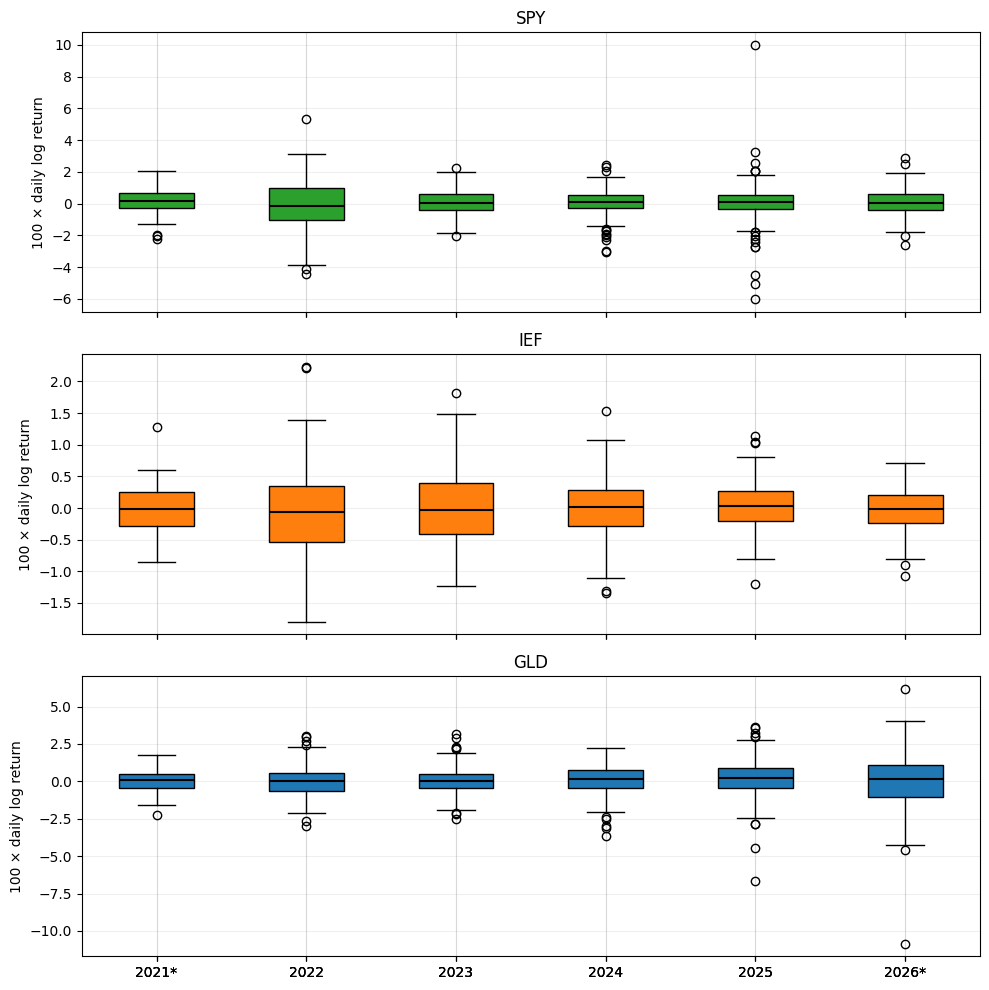

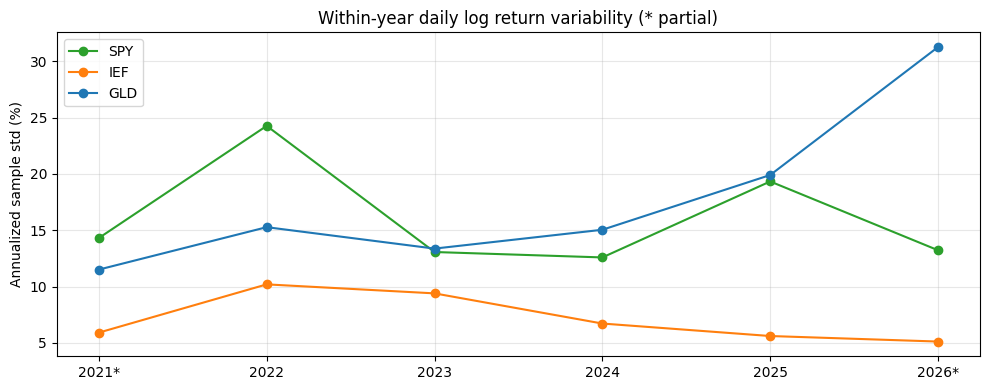

In [19]:
years = sorted(annual.year.unique())
partial_years = set(coverage.loc[coverage.partial, 'year'])
labels = [f'{y}*' if y in partial_years else str(y) for y in years]
colors = {'SPY':'tab:green', 'IEF':'tab:orange', 'GLD':'tab:blue'}
fig, axes = plt.subplots(3, 1, figsize=(10,10), sharex=True)
for ax, ticker in zip(axes, ['SPY','IEF','GLD']):
    series = [annual.loc[(annual.ticker == ticker) & (annual.year == y), 'log_return'].dropna()*100 for y in years]
    bp = ax.boxplot(series, tick_labels=labels, patch_artist=True, showfliers=True, medianprops={'color': 'black', 'linewidth': 1.5})
    for box in bp['boxes']: box.set_facecolor(colors[ticker])
    ax.set_title(ticker); ax.set_ylabel('100 × daily log return'); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(10,4))
for ticker in ['SPY','IEF','GLD']:
    ax.plot(range(len(years)), annual_std[ticker], marker='o', color=colors[ticker], label=ticker)
ax.set_xticks(range(len(years)), labels); ax.set_ylabel('Annualized sample std (%)'); ax.set_title('Within-year daily log return variability (* partial)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()


### Correlation รายปี
Pearson correlation ใช้วันร่วมที่มี return ครบทั้งสามสินทรัพย์ในแต่ละปี ไม่เติมค่าว่าง หากวันร่วมมีน้อยกว่า 2 วันหรือ variance เป็นศูนย์จะแสดง NaN ค่าใกล้ศูนย์หมายถึงความสัมพันธ์เชิงเส้นต่ำ ไม่ได้พิสูจน์ความเป็นอิสระ และความต่างระหว่างปียังไม่ได้ทดสอบนัยสำคัญ


,year,common_days,SPY-IEF,SPY-GLD,IEF-GLD,period
0,2021,68,-0.335,0.009,0.332,partial study year
1,2022,251,0.188,0.193,0.456,full study year
2,2023,250,0.044,0.002,0.550,full study year
3,2024,252,0.072,0.266,0.268,full study year
4,2025,250,-0.087,0.022,0.083,full study year
5,2026,184,0.422,0.377,0.297,partial study year


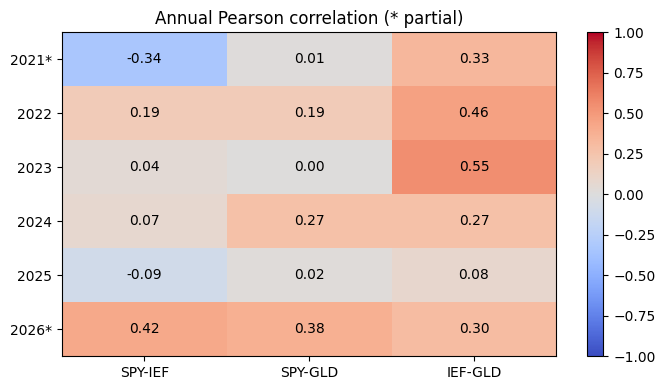

In [20]:
annual_corr = annual_correlations(annual, config['source']['tickers'], pairs)
annual_corr['period'] = np.where(annual_corr.year.isin(partial_years), 'partial study year', 'full study year')
display(annual_corr.round(3))
corr_cols = [f'{a}-{b}' for a,b in pairs]
fig, ax = plt.subplots(figsize=(7,4))
values = annual_corr[corr_cols].to_numpy(dtype=float)
cmap = plt.get_cmap('coolwarm').copy(); cmap.set_bad('lightgrey')
im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(corr_cols)), corr_cols); ax.set_yticks(range(len(years)), labels)
for i in range(len(years)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f'{values[i,j]:.2f}' if np.isfinite(values[i,j]) else 'NA', ha='center', va='center')
ax.set_title('Annual Pearson correlation (* partial)'); fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


Correlation รายปีสรุปวันภายในปี ส่วนกราฟ rolling correlation 20 วันด้านล่างแสดงความเปลี่ยนแปลงภายในปี ทั้งสองมีหน้าต่างและจำนวนข้อมูลต่างกันจึงไม่จำเป็นต้องเท่ากัน การแบ่งปีเป็นเครื่องมือสำรวจ ไม่ได้พิสูจน์ว่าตลาดเปลี่ยน regime ในวันที่ 1 มกราคม


In [21]:
# สรุปจากผลปัจจุบัน พร้อมช่วงเวลาของปีไม่เต็ม
for year in years:
    cov = coverage.loc[coverage.year.eq(year)]
    leaders = annual_std.loc[year]
    winner = leaders.idxmax() if leaders.notna().any() else 'คำนวณไม่ได้'
    period = 'ไม่เต็มปี' if year in partial_years else 'เต็มปีตามขอบเขต'
    print(f'{year} ({period}; {cov.iloc[0].days} วัน, {cov.iloc[0]["first"]:%Y-%m-%d} ถึง {cov.iloc[0]["last"]:%Y-%m-%d}): annualized std สูงสุด {winner} {leaders.max():.2f}%')
for col in corr_cols:
    vals = annual_corr[col].dropna()
    if len(vals): print(f'{col}: correlation รายปีอยู่ระหว่าง {vals.min():.3f} ถึง {vals.max():.3f}; เปลี่ยนเครื่องหมาย: {bool((vals < 0).any() and (vals > 0).any())}')
print('ค่า skewness และ kurtosis รายปีในตารางแสดงว่ารูปร่างการกระจายอาจต่างจากค่ารวมทั้งช่วง; การเปรียบเทียบเป็นเชิงพรรณนา')
print('สำหรับการพยากรณ์ ควรตรวจความเสถียรตามเวลาและระวัง historical correlation proxy เปลี่ยนได้ โดยไม่สรุปเหตุและผลจากกราฟ')

for ticker in config['source']['tickers']:
    rv = annual_rv.xs(ticker, level='ticker')
    y = rv['median'].idxmax()
    z = (rv['maximum'] - rv['median']).idxmax()
    print(f'{ticker}: median RV สูงสุดในช่วงปี {y} = {rv.loc[y, "median"]:.2f}% (p90 {rv.loc[y, "p90"]:.2f}%); ช่องว่าง max–median สูงสุดปี {z}: {rv.loc[z, "maximum"]:.2f}% เทียบกับ {rv.loc[z, "median"]:.2f}%')
    shape = yearly_shape.xs(ticker, level='ticker')
    print(f'{ticker}: excess kurtosis รายปี {shape.excess_kurtosis.min():.2f} ถึง {shape.excess_kurtosis.max():.2f}; รวมทั้งช่วง {returns_summary.loc[ticker, "kurtosis_excess"]:.2f}')
print('ช่องว่าง max–median สูงชี้ว่ามีช่วงสูงเฉพาะบางเวลา ขณะที่ median และ p90 สูงพร้อมกันสะท้อนระดับสูงกว้างกว่าในช่วงที่ศึกษา; ปีไม่เต็มอ่านประกอบจำนวนวันด้านบน')


2021 (ไม่เต็มปี; 68 วัน, 2021-09-27 ถึง 2021-12-31): annualized std สูงสุด SPY 14.31%
2022 (เต็มปีตามขอบเขต; 251 วัน, 2022-01-03 ถึง 2022-12-30): annualized std สูงสุด SPY 24.26%
2023 (เต็มปีตามขอบเขต; 250 วัน, 2023-01-03 ถึง 2023-12-29): annualized std สูงสุด GLD 13.37%
2024 (เต็มปีตามขอบเขต; 252 วัน, 2024-01-02 ถึง 2024-12-31): annualized std สูงสุด GLD 15.04%
2025 (เต็มปีตามขอบเขต; 250 วัน, 2025-01-02 ถึง 2025-12-31): annualized std สูงสุด GLD 19.90%
2026 (ไม่เต็มปี; 184 วัน, 2026-01-02 ถึง 2026-09-25): annualized std สูงสุด GLD 31.25%
SPY-IEF: correlation รายปีอยู่ระหว่าง -0.335 ถึง 0.422; เปลี่ยนเครื่องหมาย: True
SPY-GLD: correlation รายปีอยู่ระหว่าง 0.002 ถึง 0.377; เปลี่ยนเครื่องหมาย: False
IEF-GLD: correlation รายปีอยู่ระหว่าง 0.083 ถึง 0.550; เปลี่ยนเครื่องหมาย: False
ค่า skewness และ kurtosis รายปีในตารางแสดงว่ารูปร่างการกระจายอาจต่างจากค่ารวมทั้งช่วง; การเปรียบเทียบเป็นเชิงพรรณนา
สำหรับการพยากรณ์ ควรตรวจความเสถียรตามเวลาและระวัง historical correlation proxy เปลี่ยนได้ โดยไม่

## ACF: ผลตอบแทนและขนาดการเคลื่อนไหวสัมพันธ์กับอดีตหรือไม่?

ใช้ log return รายวันในช่วง analysis แยกแต่ละสินทรัพย์ เรียงวันตามปฏิทินตลาด ตรวจวันครบและ finite โดยคงวันสุดขั้วไว้ ไม่รวม warm-up

Return (`r`) มีทั้งทิศทางและขนาด; absolute return (`|r|`) สนใจขนาดโดยไม่สนเครื่องหมาย; squared return (`r²`) เพิ่มน้ำหนักวันที่เคลื่อนไหวรุนแรง ทั้งสองเป็นขนาดการเคลื่อนไหวรายวัน ไม่ใช่ historical RV แบบ rolling

สำหรับค่าเฉลี่ยทั้งชุด \(\bar{x}\) และ \(z_t=x_t-\bar{x}\), sample ACF ที่ lag k คือ \(\sum_{t=k}^{n-1}z_tz_{t-k}/\sum_{t=0}^{n-1}z_t^2\) ใช้ตัวหารเดียวทุก lag โดยไม่ปรับตาม n−k ค่า lag 0 เท่ากับ 1 เมื่อคำนวณได้ แต่กราฟแสดง lag 1–20 วันซื้อขายเท่านั้น

RV20 ของวันติดกันใช้ return ร่วมกัน 19 วัน ความต่อเนื่องบางส่วนจึงเกิดจากหน้าต่างซ้อนกัน เราจึงเริ่มสำรวจจากข้อมูลรายวันทั้งสามแบบ


In [22]:
# เตรียม ACF โดยตรวจวันและ return ก่อนคำนวณ
from src.eda.quality import sample_acf
expected_acf = pd.DatetimeIndex(expected_sessions).tz_localize(None).normalize()
expected_acf = expected_acf[(expected_acf >= start_date) & (expected_acf <= end_date)]
acf_input = analysis.loc[analysis.date.between(start_date, end_date)].copy()
if acf_input.duplicated(['date', 'ticker']).any():
    raise ValueError('ACF: พบ date/ticker ซ้ำ')
acf_values = {}
acf_rows = []
for ticker in config['source']['tickers']:
    group = acf_input.loc[acf_input.ticker.eq(ticker)].sort_values('date')
    dates = pd.DatetimeIndex(group.date)
    if not dates.equals(expected_acf):
        raise ValueError(f'ACF: {ticker} มีวันซื้อขายขาดหรือเกินช่วงที่กำหนด')
    r = group.log_return.to_numpy(dtype=float)
    if not np.isfinite(r).all():
        raise ValueError(f'ACF: {ticker} มี log return ที่ไม่ใช่ finite')
    with np.errstate(over='ignore', invalid='ignore'):
        series = {'Return': r, 'Absolute return': np.abs(r), 'Squared return': np.square(r)}
    for kind, values in series.items():
        if not np.isfinite(values).all():
            raise ValueError(f'ACF: {ticker} {kind} ไม่เป็น finite หลังแปลงข้อมูล')
        result = sample_acf(values, 20)
        acf_values[(ticker, kind)] = result
        acf_rows.append({'สินทรัพย์': ticker, 'ชนิดข้อมูล': kind, 'n': len(values),
                         **{f'lag {k}': result[k] for k in (1, 5, 10, 20)}})
acf_summary = pd.DataFrame(acf_rows)


### กราฟ ACF รายวัน
แกน Y ใช้สเกลเดียวกันทุก panel; ค่าที่คำนวณไม่ได้ไม่แทนด้วยศูนย์ ไม่มีเส้น confidence band หรือการทดสอบนัยสำคัญในส่วนนี้


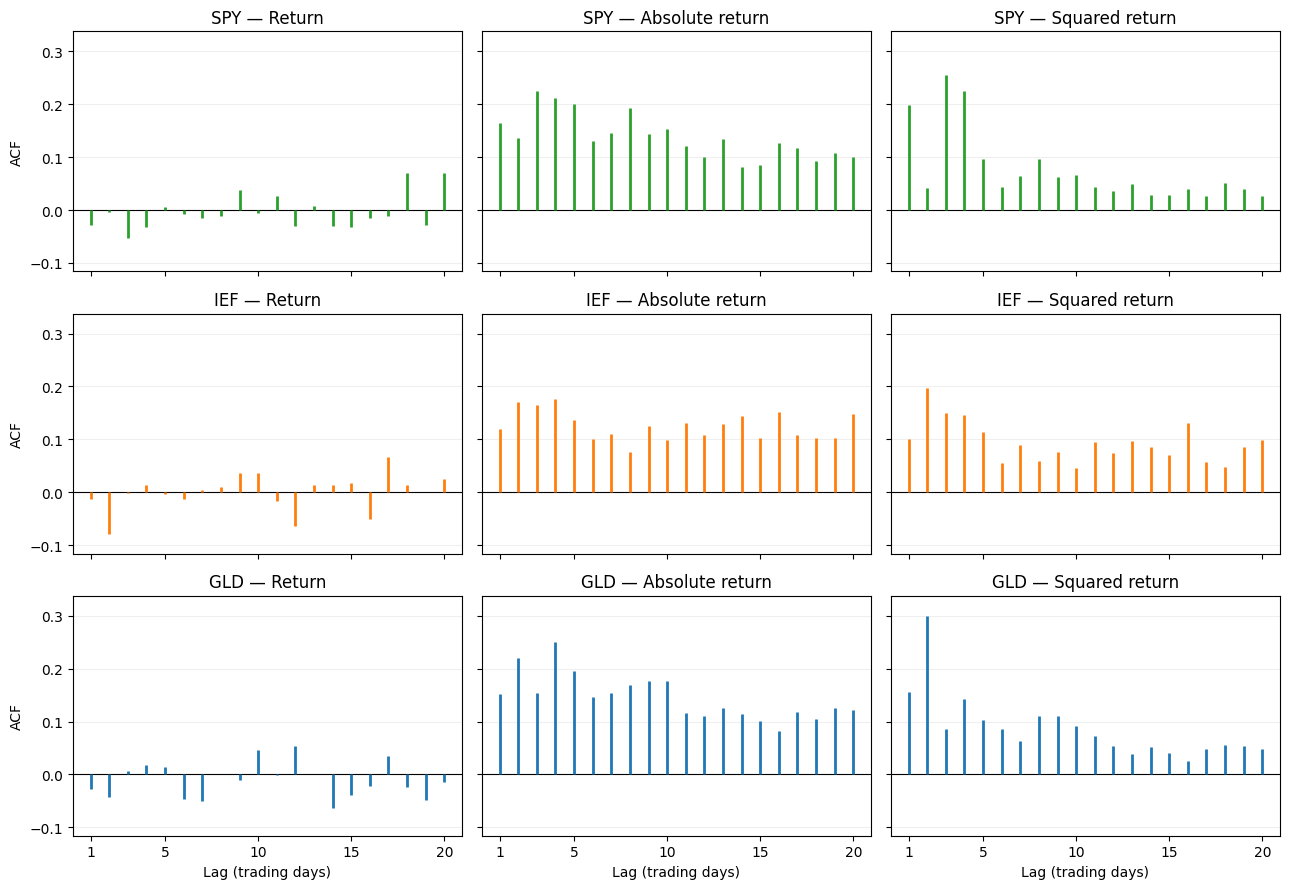

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True, sharey=True)
tickers_acf = ['SPY', 'IEF', 'GLD']
kinds_acf = ['Return', 'Absolute return', 'Squared return']
finite_acf = np.concatenate([v[1:][np.isfinite(v[1:])] for v in acf_values.values()])
if finite_acf.size:
    lo, hi = min(0., finite_acf.min()), max(0., finite_acf.max())
    padding = max((hi-lo)*.1, .02)
    limits = (lo-padding, hi+padding)
else:
    limits = (-1, 1)
for i, ticker in enumerate(tickers_acf):
    for j, kind in enumerate(kinds_acf):
        ax = axes[i,j]
        vals = acf_values[(ticker, kind)][1:]
        valid = np.isfinite(vals)
        ax.axhline(0, color='black', linewidth=.8)
        if valid.any():
            ax.vlines(np.arange(1,21)[valid], 0, vals[valid], color=colors[ticker], linewidth=2)
            if not valid.all(): ax.text(.5,.9,'Some lags unavailable', transform=ax.transAxes, ha='center')
        else:
            ax.text(.5,.5,'ACF unavailable', transform=ax.transAxes, ha='center')
        ax.set_title(f'{ticker} — {kind}')
        ax.set_ylim(*limits); ax.set_xticks([1,5,10,15,20]); ax.grid(axis='y', alpha=.2)
        if i == 2: ax.set_xlabel('Lag (trading days)')
        if j == 0: ax.set_ylabel('ACF')
plt.tight_layout(); plt.show()


### ค่าที่เลือกดู
`n` คือจำนวนข้อมูลทั้งชุด ส่วน numerator ของ lag k ใช้ n−k คู่ (เมื่อ k < n) ค่า NaN หมายถึงคำนวณไม่ได้


In [24]:
display(acf_summary.round(4))


,สินทรัพย์,ชนิดข้อมูล,n,lag 1,lag 5,lag 10,lag 20
0,SPY,Return,1255,-0.0275,0.0061,-0.0047,0.0696
1,SPY,Absolute return,1255,0.1648,0.2011,0.1528,0.1009
2,SPY,Squared return,1255,0.1991,0.0974,0.0661,0.0274
3,IEF,Return,1255,-0.0132,-0.0028,0.0369,0.0259
4,IEF,Absolute return,1255,0.1201,0.1366,0.0983,0.1477
5,IEF,Squared return,1255,0.1008,0.1137,0.0449,0.0982
6,GLD,Return,1255,-0.0268,0.0142,0.0467,-0.0135
7,GLD,Absolute return,1255,0.1527,0.1954,0.1758,0.1211
8,GLD,Squared return,1255,0.1551,0.1036,0.0906,0.0482


### ผลที่พบและข้อจำกัด
เปรียบเทียบ lag ที่แสดงในตารางกับรูปแบบครบ 20 lag ในกราฟ: การยกกำลังสองให้น้ำหนักวันรุนแรงมากขึ้น จึงควรอ่านร่วมกับการตรวจ extreme events และ sensitivity analysis

ACF ตรวจความสัมพันธ์กับอดีตเฉพาะบางรูปแบบ ข้อมูลรวมทั้งช่วงอาจรวมความผันผวนต่างระดับกันตามปี จึงควรอ่านร่วมกับผลรายปี; abs/r² ไม่ใช่ conditional volatility โดยตรง การพบ autocorrelation ไม่ยืนยันความสามารถพยากรณ์นอกตัวอย่าง การเลือก lag และประเมินโมเดลต้องทำบน training/validation ตามเวลา


In [25]:
for ticker in tickers_acf:
    print(f'{ticker}:')
    for kind in kinds_acf:
        v = acf_values[(ticker, kind)]
        values = ', '.join(f'lag {k} = {v[k]:+.3f}' if np.isfinite(v[k]) else f'lag {k} = ไม่สามารถคำนวณ' for k in (1, 5, 10, 20))
        print(f'  {kind}: {values}')
    ret = acf_values[(ticker, 'Return')][1:]
    absolute = acf_values[(ticker, 'Absolute return')][1:]
    squared = acf_values[(ticker, 'Squared return')][1:]
    if np.isfinite(ret).all() and np.isfinite(absolute).all() and np.isfinite(squared).all():
        print(f'  Return: ช่วง lag 1–20 อยู่ระหว่าง {ret.min():+.3f} ถึง {ret.max():+.3f}; เครื่องหมายดูได้ในกราฟ')
        if (absolute > 0).all() and (squared > 0).all():
            print('  Absolute และ squared return เป็นบวกตลอด lag ที่ตรวจ สอดคล้องกับความต่อเนื่องของขนาดการเคลื่อนไหวเชิงพรรณนา')
        print(f'  เทียบ lag 5 และ 20: absolute {absolute[4]:+.3f}, {absolute[19]:+.3f}; squared {squared[4]:+.3f}, {squared[19]:+.3f} (ไม่ได้แปลว่าลดลงทุก lag)')
print('ตัวเลขและกราฟเป็นข้อค้นพบเชิงพรรณนา ไม่ใช่หลักฐานนัยสำคัญหรือความแม่นยำในการพยากรณ์')


SPY:
  Return: lag 1 = -0.028, lag 5 = +0.006, lag 10 = -0.005, lag 20 = +0.070
  Absolute return: lag 1 = +0.165, lag 5 = +0.201, lag 10 = +0.153, lag 20 = +0.101
  Squared return: lag 1 = +0.199, lag 5 = +0.097, lag 10 = +0.066, lag 20 = +0.027
  Return: ช่วง lag 1–20 อยู่ระหว่าง -0.053 ถึง +0.070; เครื่องหมายดูได้ในกราฟ
  Absolute และ squared return เป็นบวกตลอด lag ที่ตรวจ สอดคล้องกับความต่อเนื่องของขนาดการเคลื่อนไหวเชิงพรรณนา
  เทียบ lag 5 และ 20: absolute +0.201, +0.101; squared +0.097, +0.027 (ไม่ได้แปลว่าลดลงทุก lag)
IEF:
  Return: lag 1 = -0.013, lag 5 = -0.003, lag 10 = +0.037, lag 20 = +0.026
  Absolute return: lag 1 = +0.120, lag 5 = +0.137, lag 10 = +0.098, lag 20 = +0.148
  Squared return: lag 1 = +0.101, lag 5 = +0.114, lag 10 = +0.045, lag 20 = +0.098
  Return: ช่วง lag 1–20 อยู่ระหว่าง -0.078 ถึง +0.066; เครื่องหมายดูได้ในกราฟ
  Absolute และ squared return เป็นบวกตลอด lag ที่ตรวจ สอดคล้องกับความต่อเนื่องของขนาดการเคลื่อนไหวเชิงพรรณนา
  เทียบ lag 5 และ 20: absolute +0.13

## กราฟประกอบ

ใช้ Matplotlib ที่ติดตั้งจากกลุ่ม dependencies `eda` และ import ไว้บนสุดแล้ว กราฟราคาเริ่มที่ 100 ในช่วงวิเคราะห์ และ RV แสดงเป็นเปอร์เซ็นต์ต่อปี

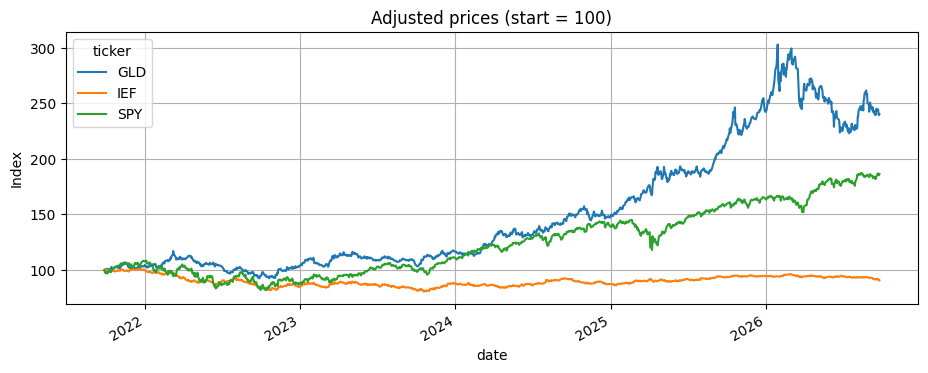

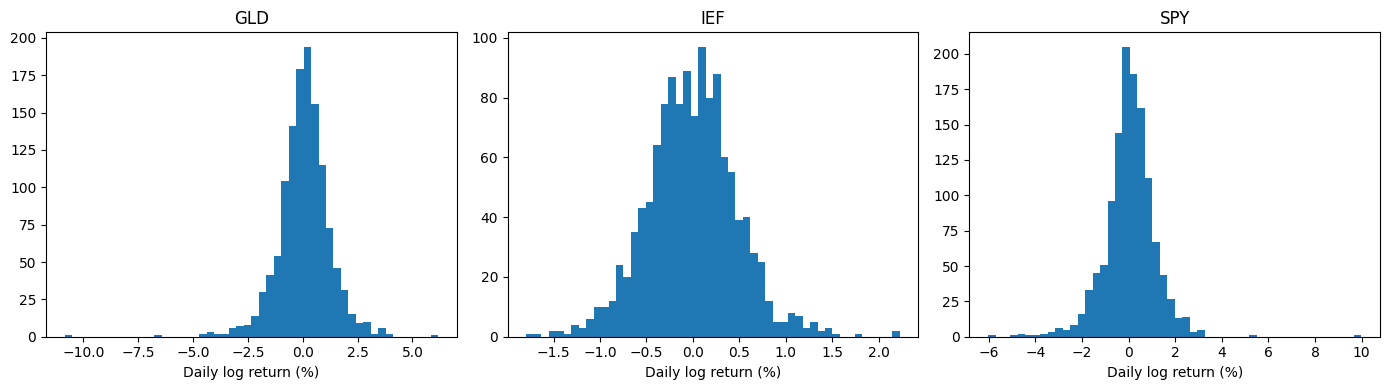

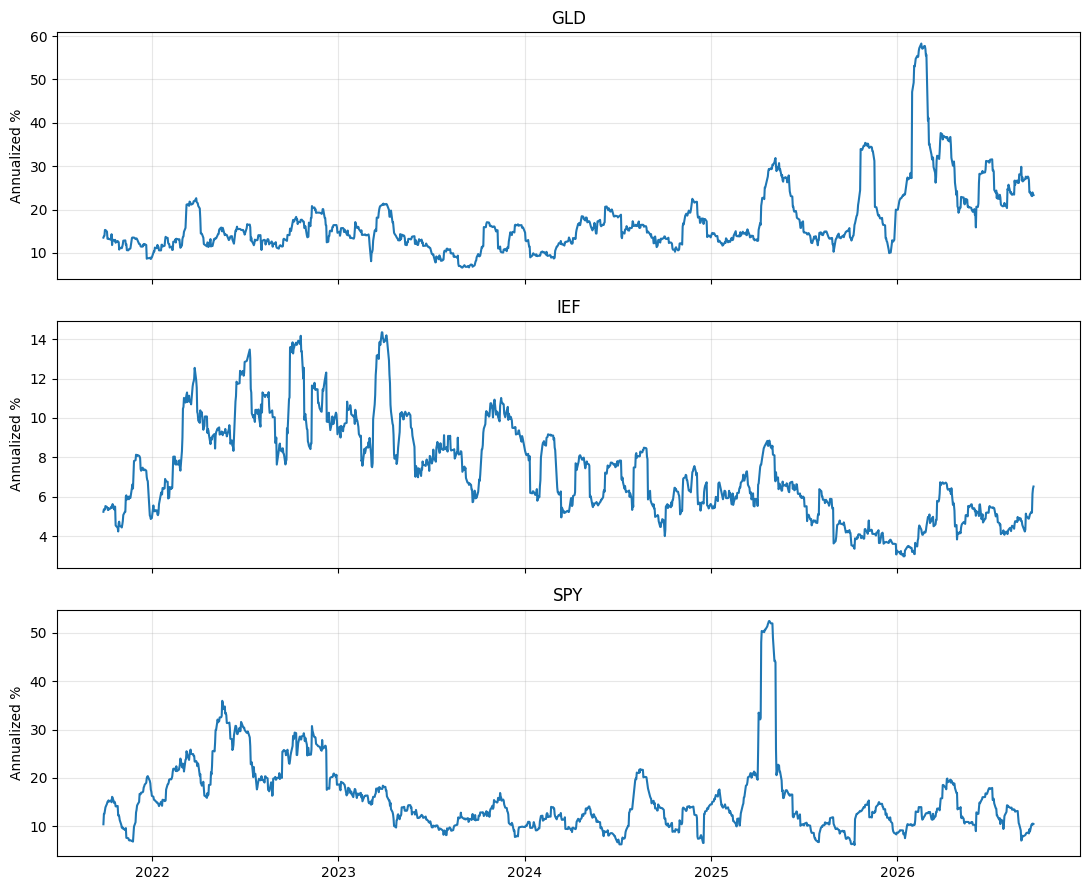

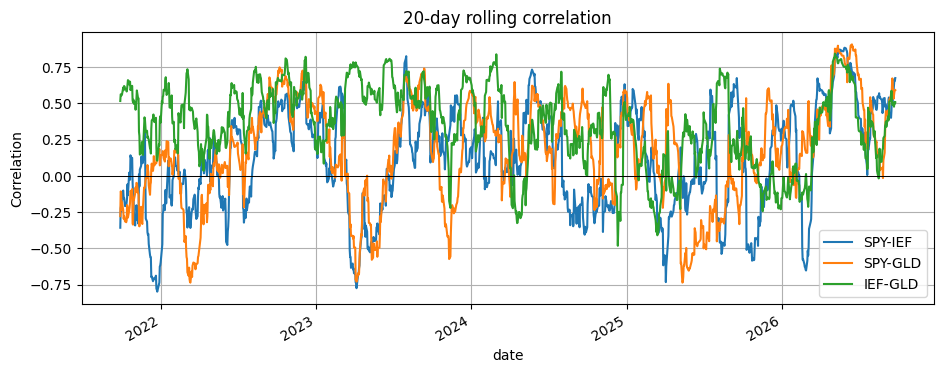

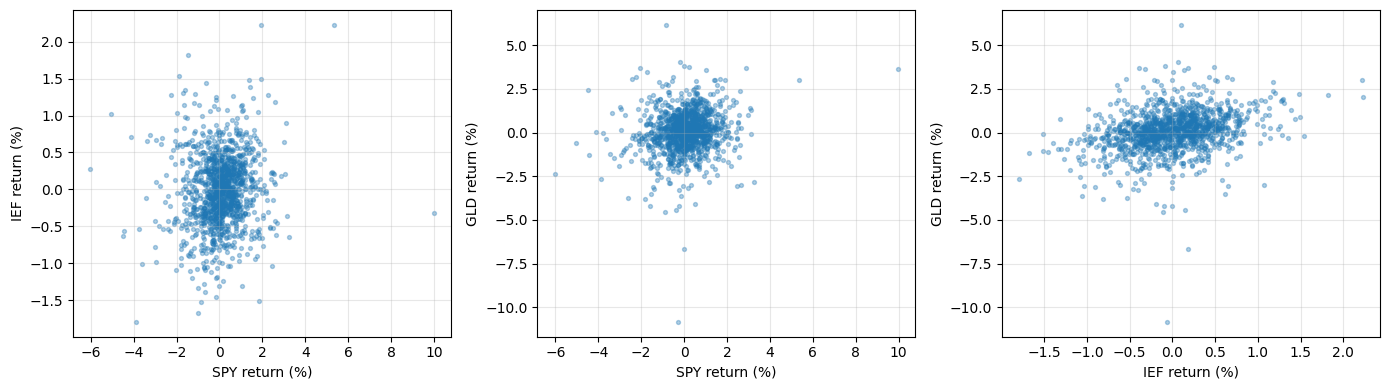

In [26]:
prices = analysis.pivot(index='date', columns='ticker', values='adjusted_close').sort_index()
(prices / prices.iloc[0] * 100).plot(title='Adjusted prices (start = 100)', figsize=(11,4), grid=True)
plt.ylabel('Index'); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, (ticker, g) in zip(axes, analysis.groupby('ticker')):
    ax.hist(g.log_return.dropna() * 100, bins=50)
    ax.set_title(ticker); ax.set_xlabel('Daily log return (%)')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(3, 1, figsize=(11,9), sharex=True)
for ax, (ticker, g) in zip(axes, analysis.groupby('ticker')):
    ax.plot(g.date, g.rv_20d * 100, label='20-day RV')
    ax.set_title(ticker); ax.set_ylabel('Annualized %'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
rolling_corr.plot(figsize=(11,4), title='20-day rolling correlation', grid=True)
plt.axhline(0, color='black', linewidth=.7); plt.ylabel('Correlation'); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, (a,b) in zip(axes, pairs):
    ax.scatter(analysis_wide[a]*100, analysis_wide[b]*100, alpha=.35, s=8)
    ax.set_xlabel(a + ' return (%)'); ax.set_ylabel(b + ' return (%)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## การนำผลไปใช้
- ตรวจวันผลตอบแทนสุดขั้วกับข้อมูลต้นทางก่อนตัดสินใจจัดการ ไม่ลบข้อมูลโดยอัตโนมัติ
- เปรียบเทียบ RV และ rolling correlation หลายช่วงเวลา เพราะความเสี่ยงและความสัมพันธ์อาจเปลี่ยนได้
- ผลสำรวจทั้งช่วงเป็น descriptive analysis; เกณฑ์ feature/model ต้องพัฒนาจาก training เท่านั้น และแบ่งข้อมูลตามเวลาเพื่อป้องกัน leakage
- Notebook นี้เป็นการสำรวจ ไม่ได้เผยแพร่ feature, correlation หรือ target pipeline; target ต้องใช้ผลตอบแทนอนาคต t+1 ถึง t+5 ตาม contract


## ข้อค้นพบเบื้องต้นจากข้อมูลชุดปัจจุบัน

- ช่วงวิเคราะห์มี 1,255 วันต่อสินทรัพย์ ไม่พบคีย์ซ้ำ วันซื้อขายขาด หรือราคาที่ไม่ผ่านการตรวจเบื้องต้น; return ที่ว่างมี 3 ค่าในช่วง warm-up
- ส่วนเบี่ยงเบนมาตรฐานรายวันของ log return: GLD 1.19%, SPY 1.08%, IEF 0.49%; GLD และ SPY มี excess kurtosis ประมาณ 7.69 และ 7.92 ตามลำดับ แสดงหางหนักเมื่อเทียบกับ normal
- correlation ตลอดช่วงของ SPY–IEF, SPY–GLD และ IEF–GLD เท่ากับ 0.097, 0.152 และ 0.300 แต่ rolling 20 วันเปลี่ยนจากลบเป็นบวกได้มาก จึงไม่ควรสมมติว่าความสัมพันธ์คงที่
- GLD วันที่ 2026-01-30 มี simple return ประมาณ -10.27% (log return -0.10841) มีหลักฐานภายนอกสนับสนุนขนาดการเคลื่อนไหวโดยประมาณ แต่ยังไม่ยืนยัน adjusted return ทุกหลัก แม้ไม่ถูก flag ตามเกณฑ์ simple return ±20%
- ข้อค้นพบนี้เป็นการพรรณนาข้อมูลชุดปัจจุบัน ไม่ใช่ผลประเมินโมเดลนอกตัวอย่าง

- ค่า std, kurtosis และ correlation ขึ้นอยู่กับเหตุการณ์ที่เลือกเปรียบเทียบตามตาราง sensitivity; ข้อมูลเต็มยังเป็นผลหลัก และเหตุการณ์ตลาดจริงเป็นส่วนหนึ่งของความเสี่ยง ไม่ใช่คำสั่งตัดข้อมูล

### ผลตามปีและข้อจำกัด
ดูตารางและข้อค้นพบรายปีด้านบนร่วมกับผลรวมทั้งช่วง ปีที่มีเครื่องหมาย * ไม่เต็มตามขอบเขตศึกษาและไม่ใช่ผลแทนทั้งปี จำนวนวันซื้อขายที่ขาดแสดงแยกในตาราง coverage

### ความสัมพันธ์กับอดีต
ดู ACF ของ return, absolute return และ squared return รายวันข้างต้นร่วมกับข้อมูลรายปีและการตรวจเหตุการณ์สุดขั้ว ผลนี้เป็นสมมติฐานสำหรับศึกษาต่อ ไม่ยืนยันผลพยากรณ์นอกตัวอย่าง
